# Comparación de Rendimiento y Speedup

Este cuaderno corresponde al paso 6 del proyecto. Compara los tiempos de la solución secuencial con los de la solución paralela y calcula la aceleración obtenida en cada fase. Solo lee los resultados guardados por los cuadernos anteriores, por lo que no necesita la GPU ni el dataset.

La aceleración, o speedup, indica cuántas veces más rápida es la versión paralela que la secuencial. Se calcula como S = T secuencial / T paralelo. Un valor mayor que 1 indica una mejora, y un valor menor que 1 indica que la versión paralela es más lenta.

## Carga de Resultados

In [1]:
import sys
from pathlib import Path

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT))

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from src import config

R = config.RESULTS_DIR
seq = pd.read_csv(R / "sequential_times.csv")
seq = seq[seq["note"] != "first"]
seq_epochs = pd.read_csv(R / "sequential_epochs.csv")
cpu_par = pd.read_csv(R / "02_cpu_parallel_times.csv")
cpu_par = cpu_par[cpu_par["rep"] > 0]
numba = pd.read_csv(R / "02_numba_times.csv")
numba = numba[numba["rep"] > 0]
gpu = pd.read_csv(R / "gpu_times.csv")
gpu_epochs = pd.read_csv(R / "gpu_epochs.csv")

n_max = int(cpu_par["workers"].max())
print("Repeticiones secuenciales por fase:", seq.groupby("phase").size().to_dict())
print("Repeticiones en GPU por fase:", gpu.groupby("phase").size().to_dict())
print("Procesos de la configuración paralela:", n_max)

Repeticiones secuenciales por fase: {'inference': 3, 'preprocess': 5, 'train': 3}
Repeticiones en GPU por fase: {'inference': 3, 'train': 3, 'transfer_h2d': 3}
Procesos de la configuración paralela: 32


## Tabla Comparativa de Tiempos

La versión secuencial corresponde al preprocesamiento en un núcleo y al entrenamiento y la inferencia en el CPU. La versión paralela corresponde al preprocesamiento con todos los núcleos lógicos y al entrenamiento y la inferencia en la GPU. El total suma las tres fases.

In [2]:
def stats(values):
    """Promedio y desviación estándar muestral de una serie de tiempos."""
    return values.mean(), values.std(ddof=1)


phases = {
    "Preparación de datos": (seq.loc[seq["phase"] == "preprocess", "seconds"],
                             cpu_par.loc[cpu_par["workers"] == n_max, "seconds"]),
    "Entrenamiento": (seq.loc[seq["phase"] == "train", "seconds"],
                      gpu.loc[gpu["phase"] == "train", "seconds"]),
    "Inferencia": (seq.loc[seq["phase"] == "inference", "seconds"],
                   gpu.loc[gpu["phase"] == "inference", "seconds"]),
}

rows = []
for name, (s, p) in phases.items():
    (s_mean, s_std), (p_mean, p_std) = stats(s), stats(p)
    rows.append({"fase": name, "secuencial (s)": s_mean, "desv. secuencial": s_std,
                 "paralelo (s)": p_mean, "desv. paralelo": p_std})
comparison = pd.DataFrame(rows).set_index("fase")
comparison.loc["Total"] = [comparison["secuencial (s)"].sum(), np.nan, comparison["paralelo (s)"].sum(), np.nan]
comparison["speedup"] = comparison["secuencial (s)"] / comparison["paralelo (s)"]
comparison.to_csv(R / "03_speedup.csv")
comparison.round(3)

,secuencial (s),desv. secuencial,paralelo (s),desv. paralelo,speedup
fase,,,,,
Preparación de datos,11.532,0.106,1.813,0.330,6.362
Entrenamiento,86.753,0.250,40.271,9.361,2.154
Inferencia,0.837,0.028,0.490,0.051,1.709
Total,99.123,NaN,42.574,NaN,2.328


La paralelización reduce el tiempo de las tres fases. La preparación de datos obtiene el mayor speedup (6.36), al bajar de 11.53 s a 1.81 s. El entrenamiento pasa de 86.75 s a 40.27 s (speedup de 2.15), y la inferencia de 0.84 s a 0.49 s (speedup de 1.71). En total, el flujo completo baja de 99.12 s a 42.57 s, un speedup de 2.33.

El speedup total queda cerca del speedup del entrenamiento porque esta fase sigue ocupando la mayor parte del tiempo de la versión paralela (40.27 s de 42.57 s). La alta desviación del entrenamiento en la GPU (9.36 s) se analiza en la siguiente sección.

## Speedup del Entrenamiento por Época

El tiempo total del entrenamiento en la GPU incluye la preparación inicial de CUDA y del modelo, que se concentra en la primera época. La siguiente tabla separa la primera época de las demás para distinguir ese costo fijo del rendimiento estable.

In [3]:
def epoch_split(df):
    """Promedio de la primera época y de las épocas 2 a 10."""
    return pd.Series({
        "primera época (s)": df.loc[df["epoch"] == 1, "seconds"].mean(),
        "épocas 2 a 10 (s)": df.loc[df["epoch"] > 1, "seconds"].mean(),
    })


epochs = pd.DataFrame({"CPU": epoch_split(seq_epochs), "GPU": epoch_split(gpu_epochs)})
epochs["speedup"] = epochs["CPU"] / epochs["GPU"]
display(epochs.round(3))

gpu_train = gpu.loc[gpu["phase"] == "train"].set_index("rep")["seconds"]
gpu_train.rename("entrenamiento en GPU (s)").to_frame().round(2)

,CPU,GPU,speedup
primera época (s),10.383,19.505,0.532
épocas 2 a 10 (s),8.372,2.225,3.763


,entrenamiento en GPU (s)
rep,
1,51.08
2,34.98
3,34.76


En la primera época, la GPU es más lenta que el CPU (19.51 s frente a 10.38 s, speedup de 0.53), porque en esa época TensorFlow compila las operaciones del modelo para la GPU. En las épocas 2 a 10, la GPU tarda 2.23 s por época frente a 8.37 s del CPU, un speedup de 3.76. Ese es el rendimiento estable de la GPU una vez descontado el costo inicial.

La primera repetición en la GPU tardó 51.08 s y las otras dos cerca de 34.9 s. La primera época de cada repetición tarda unos 14 s por la compilación del modelo nuevo, y en la primera repetición se suman cerca de 16 s más por la carga inicial de las librerías de CUDA y cuDNN, que ocurre una sola vez. Estos costos son fijos, por lo que mientras más épocas tenga un entrenamiento, más se acerca el speedup total al speedup estable.

## Escalabilidad de la Preparación de Datos

La eficiencia indica qué fracción del aumento ideal se obtiene. Se calcula como E = S / n, donde n es el número de procesos. Una eficiencia de 1 significa que duplicar los procesos reduce el tiempo a la mitad.

In [4]:
t_seq = phases["Preparación de datos"][0].mean()
scaling = cpu_par.groupby("workers")["seconds"].agg(["mean", "std"])
scaling["speedup"] = t_seq / scaling["mean"]
scaling["eficiencia"] = scaling["speedup"] / scaling.index
scaling.to_csv(R / "03_scaling.csv")
scaling.round(3)

,mean,std,speedup,eficiencia
workers,,,,
1,14.283,1.142,0.807,0.807
2,8.164,0.904,1.413,0.706
4,4.600,0.436,2.507,0.627
8,2.672,0.574,4.316,0.539
16,1.827,0.188,6.313,0.395
32,1.813,0.330,6.362,0.199


El speedup crece con el número de procesos hasta 16 (6.31) y luego se estanca (6.36 con 32). La eficiencia baja de 0.81 con un proceso a 0.39 con 16 y a 0.20 con 32. Con un proceso la eficiencia ya es menor que 1, porque el pool agrega el costo de coordinar los procesos y transferir los resultados. Al aumentar los procesos influyen además los 16 núcleos físicos del equipo y la parte que solo ejecuta el proceso principal (unir los bloques y normalizar), que no se reparte.

## Contraste con el Kernel de Numba

La siguiente tabla compara la preparación de datos con todos los núcleos del CPU contra la variante que redimensiona y normaliza en la GPU con el kernel propio.

In [5]:
numba_mean = numba[["decode", "h2d", "kernel", "d2h", "total"]].mean()
contrast = pd.Series({
    "CPU con todos los núcleos (s)": scaling.loc[n_max, "mean"],
    "CPU decodifica y GPU redimensiona (s)": numba_mean["total"],
})
display(contrast.round(3).to_frame("tiempo"))
numba_mean.rename("promedio (s)").to_frame().round(4)

,tiempo
CPU con todos los núcleos (s),1.813
CPU decodifica y GPU redimensiona (s),8.133


,promedio (s)
decode,6.9172
h2d,0.6543
kernel,0.1507
d2h,0.4112
total,8.1334


Mover el redimensionado a la GPU hace que la preparación de datos sea 4.5 veces más lenta (8.13 s frente a 1.81 s). El kernel solo ocupa 0.15 s. El resto del tiempo se pierde en decodificar y devolver imágenes de mayor tamaño (6.92 s) y en copiarlas entre el CPU y la GPU (1.07 s).

## Gráficas

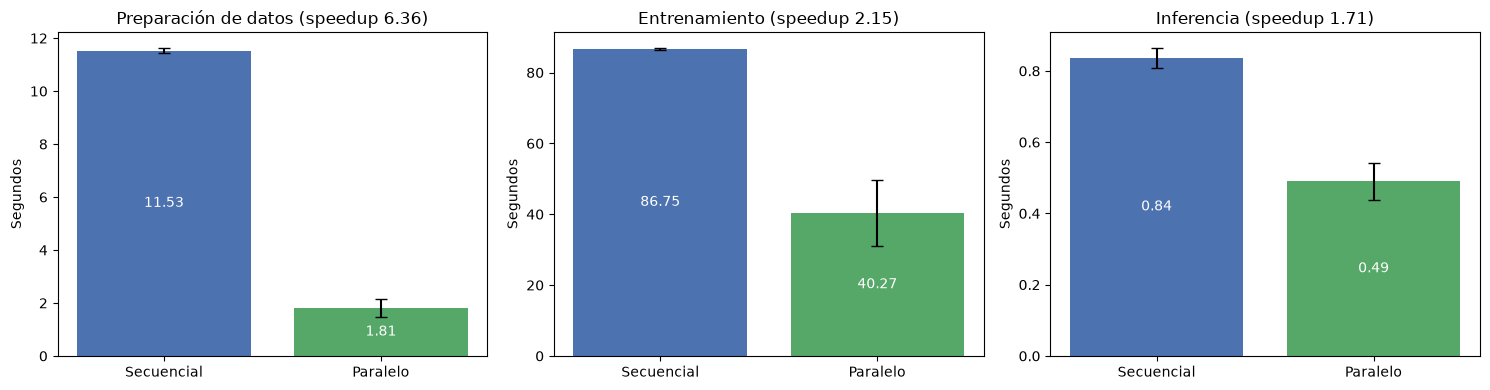

In [6]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4))
labels = ["Preparación de datos", "Entrenamiento", "Inferencia"]
for ax, name in zip(axes, labels):
    row = comparison.loc[name]
    bars = ax.bar(["Secuencial", "Paralelo"], [row["secuencial (s)"], row["paralelo (s)"]],
                  yerr=[row["desv. secuencial"], row["desv. paralelo"]], capsize=4,
                  color=["#4C72B0", "#55A868"])
    ax.set_title(f"{name} (speedup {row['speedup']:.2f})")
    ax.set_ylabel("Segundos")
    ax.bar_label(bars, fmt="%.2f", label_type="center", color="white")
fig.tight_layout()
fig.savefig(config.FIGURES_DIR / "03_times_comparison.png", dpi=150, bbox_inches="tight")
plt.show()

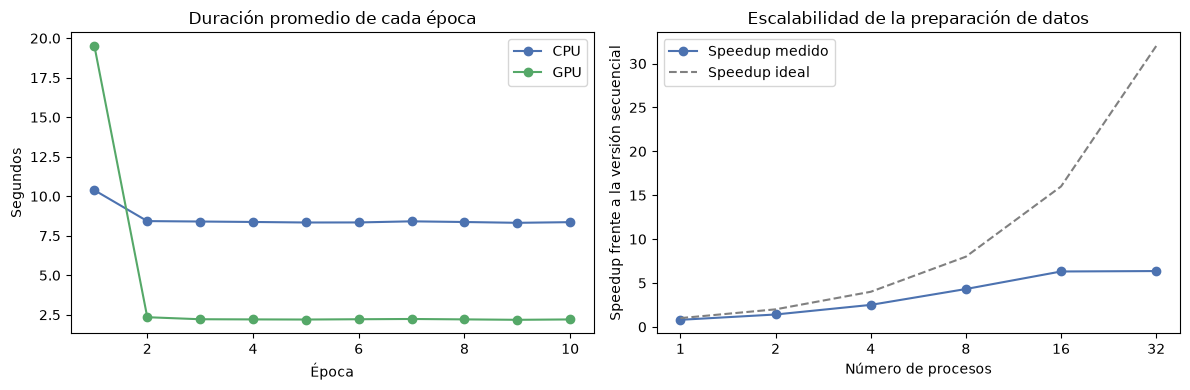

In [7]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))

for device, df, color in [("CPU", seq_epochs, "#4C72B0"), ("GPU", gpu_epochs, "#55A868")]:
    mean = df.groupby("epoch")["seconds"].mean()
    axes[0].plot(mean.index, mean.values, marker="o", color=color, label=device)
axes[0].set_title("Duración promedio de cada época")
axes[0].set_xlabel("Época")
axes[0].set_ylabel("Segundos")
axes[0].legend()

workers = scaling.index.to_numpy()
axes[1].plot(workers, scaling["speedup"], marker="o", color="#4C72B0", label="Speedup medido")
axes[1].plot(workers, workers, linestyle="--", color="gray", label="Speedup ideal")
axes[1].set_xscale("log", base=2)
axes[1].set_xticks(workers, [str(w) for w in workers])
axes[1].set_title("Escalabilidad de la preparación de datos")
axes[1].set_xlabel("Número de procesos")
axes[1].set_ylabel("Speedup frente a la versión secuencial")
axes[1].legend()

fig.tight_layout()
fig.savefig(config.FIGURES_DIR / "03_epochs_scaling.png", dpi=150, bbox_inches="tight")
plt.show()

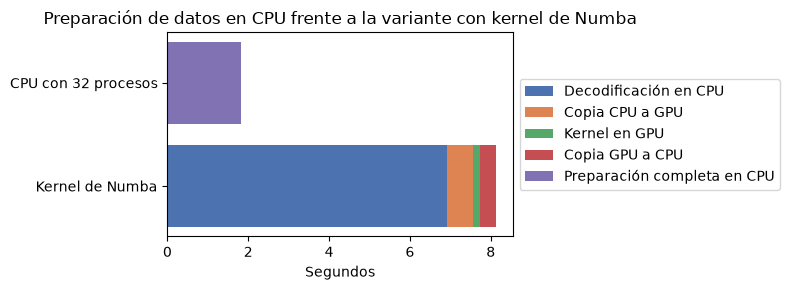

In [8]:
fig, ax = plt.subplots(figsize=(8, 3))
parts = [("decode", "Decodificación en CPU", "#4C72B0"), ("h2d", "Copia CPU a GPU", "#DD8452"),
         ("kernel", "Kernel en GPU", "#55A868"), ("d2h", "Copia GPU a CPU", "#C44E52")]
left = 0.0
for key, label, color in parts:
    ax.barh("Kernel de Numba", numba_mean[key], left=left, color=color, label=label)
    left += numba_mean[key]
ax.barh(f"CPU con {n_max} procesos", scaling.loc[n_max, "mean"], color="#8172B3", label="Preparación completa en CPU")
ax.set_xlabel("Segundos")
ax.set_title("Preparación de datos en CPU frente a la variante con kernel de Numba")
ax.legend(loc="center left", bbox_to_anchor=(1, 0.5))
fig.tight_layout()
fig.savefig(config.FIGURES_DIR / "03_numba_contrast.png", dpi=150, bbox_inches="tight")
plt.show()

## Conclusiones

- **La paralelización sí redujo los tiempos.** El flujo completo pasó de 99.12 s a 42.57 s, con un speedup total de 2.33.
- **La preparación de datos se beneficia de los núcleos del CPU.** Con 32 procesos alcanza un speedup de 6.36, aunque deja de mejorar a partir de 16 procesos, que coinciden con los núcleos físicos del equipo.
- **El entrenamiento se beneficia de la GPU.** El speedup promedio es de 2.15, y llega a 3.76 por época cuando se descuentan los costos fijos de la primera época.
- **El costo de mover datos limita el uso de la GPU en tareas ligeras.** En el redimensionado, el kernel es rápido, pero las transferencias y la decodificación hacen que la variante en GPU sea 4.5 veces más lenta que la del CPU.
- **El entrenamiento domina el tiempo de la versión paralela.** Ocupa 40.27 s de 42.57 s, por lo que es la fase que más influye en el speedup total.